# SARIMAX y Coeficientes departamentales

Como parte de nuestro proyecto, queremos pronosticar el Índice de Precios al Consumidor (IPC) según varía el tiempo y distintas variables coyunturales. Como complemento, mostraremos los pronósticos del índice a nivel departamental. El fin de este modelo es, a diferencia de pronósticos de inflación encontrados en lugares como el Banco de Guatemala, poder pronosticar al corto plazo el cambio de los precios al consumidor en algún departamento específico considerando los factores macroeconómicos y demográficos coyunturales del momento.
Para realizar el pronóstico, se utilizó el modelo estadístico SARIMAX. La fuente de información es la siguiente:

**Variable dependiente**    
- IPC: serie mensual nacional, base anual 2024 = 100. Fuente: INE.
      
**Índice temporal**    
- Tiempo: año y mes de cada observación de la serie del IPC.
      
**Variables exógenas candidatas**
- Población: población nacional estimada y proyectada, expresada en millones. Fuente: INE, Proyecciones Nacionales 1950–2050.
- El Niño: indicador binario de episodios cálidos según ONI–ERSSTv6. Fuente: NOAA–CPC.
- La Niña: indicador binario de episodios fríos según ONI–ERSSTv6. Fuente: NOAA–CPC.
- Cambios gubernamentales: elaboración propia a partir de las fechas históricas de toma de posesión presidencial en Guatemala.


Las estimaciones departamentales se obtienen multiplicando el pronóstico nacional por un coeficiente específico de cada departamento, calculado a partir de los precios recolectados por el INE.

**Información departamental**    
- Precios recolectados 2023: registros de precios por artículo y ubicación. Fuente: INE. 

A continuación, se presenta el código documentado utilizado para preparar los datos, seleccionar el modelo y evaluar sus pronósticos.

In [1]:
from pathlib import Path

#Importar las librerías necesarias para ambos modelos.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from itertools import combinations
from scipy.stats import norm
from statsforecast.models import AutoARIMA
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.sparse import csr_matrix, diags
from scipy.sparse.csgraph import connected_components
from statsforecast.models import ARIMA
from IPython.display import display

# Rutas relativas a la raíz del repositorio
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "modelos" / "ipc").is_dir())
INSUMOS = RAIZ / "modelos" / "ipc" / "insumos"
CRUDOS = RAIZ / "datos" / "crudos"  # se genera con modelos/ipc/preparar_insumos.py


## Sarimax

SARIMAX es un modelo de series de tiempo. Como dice su nombre, SARIMAX busca pronosticar series de tiempo entendiendo su estacionalidad (S), factor auto regresivo (AR), tendencia (I), promedio movil (MA) y variables exógenas (X).
Poder entender cada uno de estos factores es indispensable para generar un buen modelo. 



### 1. LEER Y VALIDAR DATOS

Como primer paso, se realizó una limpieza general de datos. Este paso es necesario para generar un modelo estandarizado y funcional. Se asume que el archivo xlsx ya contiene las 4 variables exógenas dentro de ellas.

In [2]:


# Leer el archivo y abreviar los nombres de las columnas
datos = pd.read_csv(INSUMOS / "ipc_mensual_variables_exogenas.csv", encoding="utf-8-sig").rename(columns={
    "Año": "anio", "Mes": "mes", "v": "ipc",
    "El Niño": "nino", "La niña": "nina", "Poblacion": "poblacion"
})

# Asociar cada mes con su número
meses = (
    "enero febrero marzo abril mayo junio julio agosto "
    "septiembre octubre noviembre diciembre"
).split()
numero_mes = {mes: i for i, mes in enumerate(meses, 1)}

# Crear el índice temporal mensual

datos["fecha"] = pd.to_datetime({
    "year": datos["anio"],
    "month": datos["mes"].str.strip().str.lower().map(numero_mes),
    "day": 1
})
datos = datos.set_index("fecha").sort_index()

# Expresar la población en millones y definir las variables exógenas
datos["poblacion_millones"] = datos["poblacion"] / 1e6
variables = ["cambio_gobierno", "nino", "nina", "poblacion_millones"]

### 2. PARTICIONES

Se dividen los datos en tres periodos. 
- Ajuste interno: Datos necesarios para entrenar el modelo.
- Validación interna: Datos utilizados para comparar distintos modelos y seleccionar el mejor.
- Prueba: Datos utilizados para poner a prueba el modelo seleccionado para verificar su capacidad.

In [3]:
h = 12
y = datos["ipc"].to_numpy(dtype=float)
X = datos[variables].to_numpy(dtype=float)

#Particion entrenamiento ajuste y validacion
y_train, y_test = y[:-h], y[-h:]
X_train, X_test = X[:-h], X[-h:]
y_ajuste, y_val = y_train[:-h], y_train[-h:]
X_ajuste, X_val = X_train[:-h], X_train[-h:]

print(f"Ajuste interno: {len(y_ajuste)} meses")
print(f"Validación interna: {len(y_val)} meses")
print(f"Entrenamiento final: {len(y_train)} meses; prueba: {len(y_test)} meses")

Ajuste interno: 500 meses
Validación interna: 12 meses
Entrenamiento final: 512 meses; prueba: 12 meses


### 3. FUNCIONES COMUNES

Se generan funciones necesarias para crear el modelo:
- def exogenas: función para seleccionar las variables coyunturales para cada modelo.
- def ajustar: función autoARIMA que permuta varios modelos SARIMAX hasta encontrar el que tenga las mejores métricas.
- def predecir: función para predecir con cada uno de los modelos.
- def metricas: función para medir los resultados de cada uno de los modelos.

In [4]:
def exogenas(x, columnas):
    return x[:, list(columnas)] if columnas else None


def ajustar(y, x, columnas): #El modelo 
    return AutoARIMA( 
        season_length=12,
        stepwise=False,
        approximation=False
    ).fit(np.log(y), X=exogenas(x, columnas))


def predecir(modelo, x, columnas, horizonte):
    # Convertir todos los resultados a arrays para evitar alineación por índice
    pred = {
        clave: np.asarray(valor, dtype=float)
        for clave, valor in modelo.predict(
            h=horizonte, X=exogenas(x, columnas), level=[80, 95]
        ).items()
    }

    varianza = (
        (pred["hi-95"] - pred["lo-95"]) / (2 * norm.ppf(0.975))
    ) ** 2

    return {
        "pronostico": np.exp(pred["mean"]) * (1 + varianza / 2),
        **{
            f"{extremo}_{nivel}": np.exp(pred[f"{clave}-{nivel}"])
            for nivel in [80, 95]
            for extremo, clave in [("inferior", "lo"), ("superior", "hi")]
        }
    }


def metricas(real, pred): #Metricas de validacion de modelo
    real, pred = np.asarray(real), np.asarray(pred)
    error = real - pred
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": 100 * np.mean(np.abs(error / real))
    }

### 4. COMPARAR COMBINACIONES EN VALIDACIÓN INTERNA

Se utilizan los 12 meses de validación interna para comparar todas las combinaciones de los modelos. Al final, selecciona el mejor modelo.

In [5]:


# Generar todos los conjuntos de variables, incluida la opción sin exógenas.
combinaciones = [
    columnas
    for k in range(len(variables) + 1)
    for columnas in combinations(range(len(variables)), k)
]

filas = []

for i, columnas in enumerate(combinaciones):
    # Identificar las variables incluidas en esta especificación.
    nombre = " + ".join(variables[j] for j in columnas) or "Sin exógenas"
    fila = {"id": i, "variables": nombre}

    try:
        # Ajustar y evaluar la combinación en validación interna
        ajuste = ajustar(y_ajuste, X_ajuste, columnas)
        pred = predecir(ajuste, X_val, columnas, h)
        fila.update(metricas(y_val, pred["pronostico"]), estado="OK")

    except Exception as error:
        # Registrar el fallo y continuar con la siguiente combinación
        fila.update(
            MAE=np.nan,
            RMSE=np.nan,
            MAPE=np.nan,
            estado=str(error)
        )

    filas.append(fila)

# Ordenar por menor RMSE.
candidatos = pd.DataFrame(filas).sort_values("RMSE", kind="stable")
display(candidatos.round(4))


# Elegir la mejor combinación sin utilizar los datos de prueba final.
ganador = candidatos.iloc[0]
mejores_variables = combinaciones[int(ganador["id"])]

,id,variables,MAE,RMSE,MAPE,estado
2,2,nino,0.3979,0.4528,0.3928,OK
8,8,nino + nina,0.4013,0.4563,0.3961,OK
0,0,Sin exógenas,0.4310,0.4874,0.4254,OK
3,3,nina,0.4347,0.4913,0.4290,OK
11,11,cambio_gobierno + nino + nina,0.5806,0.6392,0.5730,OK
6,6,cambio_gobierno + nina,0.6613,0.7235,0.6526,OK
9,9,nino + poblacion_millones,0.6585,0.8287,0.6494,OK
14,14,nino + nina + poblacion_millones,0.6593,0.8301,0.6503,OK
4,4,poblacion_millones,0.6601,0.8333,0.6510,OK
10,10,nina + poblacion_millones,0.6610,0.8347,0.6519,OK


### 5. REAJUSTAR

Se reajusta el modelo ganador y se evalua utilizando los 12 meses de prueba.

In [6]:
modelo_seleccionado = ajustar(y_train, X_train, mejores_variables)
pred = predecir(modelo_seleccionado, X_test, mejores_variables, h)

metricas_prueba = pd.DataFrame(
    [metricas(y_test, pred["pronostico"])], index=["Seleccionado"]
)
resultados = pd.DataFrame(
    {"observado": y_test, **pred}, index=datos.index[-h:]
)

p, q, P, Q, periodo, d, D = map(int, modelo_seleccionado.model_["arma"])
print(f"\nVariables seleccionadas: {ganador['variables']}")
print(f"SARIMAX({p},{d},{q})({P},{D},{Q})[{periodo}]")
print("\nCoeficientes:", modelo_seleccionado.model_["coef"])
print("\nMÉTRICAS DE PRUEBA")
print(metricas_prueba.round(4))
print("\nRESULTADOS")
print(resultados.round(4))


Variables seleccionadas: nino
SARIMAX(4,2,1)(0,0,0)[12]

Coeficientes: {'ar1': np.float64(-0.050953917415262104), 'ar2': np.float64(-0.09756791213503732), 'ar3': np.float64(-0.04327742367148318), 'ar4': np.float64(-0.1851435956650367), 'ma1': np.float64(-0.6654938911758311), 'ex_1': np.float64(-0.0005856136520037789)}

MÉTRICAS DE PRUEBA
                 MAE    RMSE    MAPE
Seleccionado  1.3751  1.7366  1.3092

RESULTADOS
            observado  pronostico  inferior_80  superior_80  inferior_95  \
fecha                                                                      
2025-11-01   102.0957    101.8881     100.6626     103.1193     100.0222   
2025-12-01   102.1687    102.0285     100.0348     104.0376      99.0013   
2026-01-01   101.9851    102.1687      99.4522     104.9137      98.0548   
2026-02-01   102.3341    102.2716      98.8063     105.7834      97.0379   
2026-03-01   103.3813    102.3824      98.2363     106.5953      96.1357   
2026-04-01   104.3332    102.4343      97

El modelo final utilizá el fenómeno del niño para predecir mejor (consideró las otras variables innecesarias). Encontro que los siguientes parámetros son los mejores para predecir:

SARIMAX(4,2,1)(0,0,0)[12]

- Cada periodo depende de los cuatro periodos anteriores como punto de partida.
- La tendencia de los datos se puede linealizar diferenciandola dos veces.
- Considera el error del período anterior para ajustar el pronóstico.
- Asume que no hay estacionalidad entre los años.


### 6. DIAGNÓSTICO DE RESIDUOS Y GRÁFICOS

Una vez seleccionado el mejor modelo, debemos asegurarnos de que sea "adecuado" utilizarlo. El modelo SARIMAX sigue ciertos supuestos estadísticos que son indispensables validar antes de empezar a utilizarlo. 
Si el modelo fallara alguno de estos modelos, es necesario corregirlo.


LJUNG–BOX
    lb_stat  lb_pvalue
24  64.4913        0.0


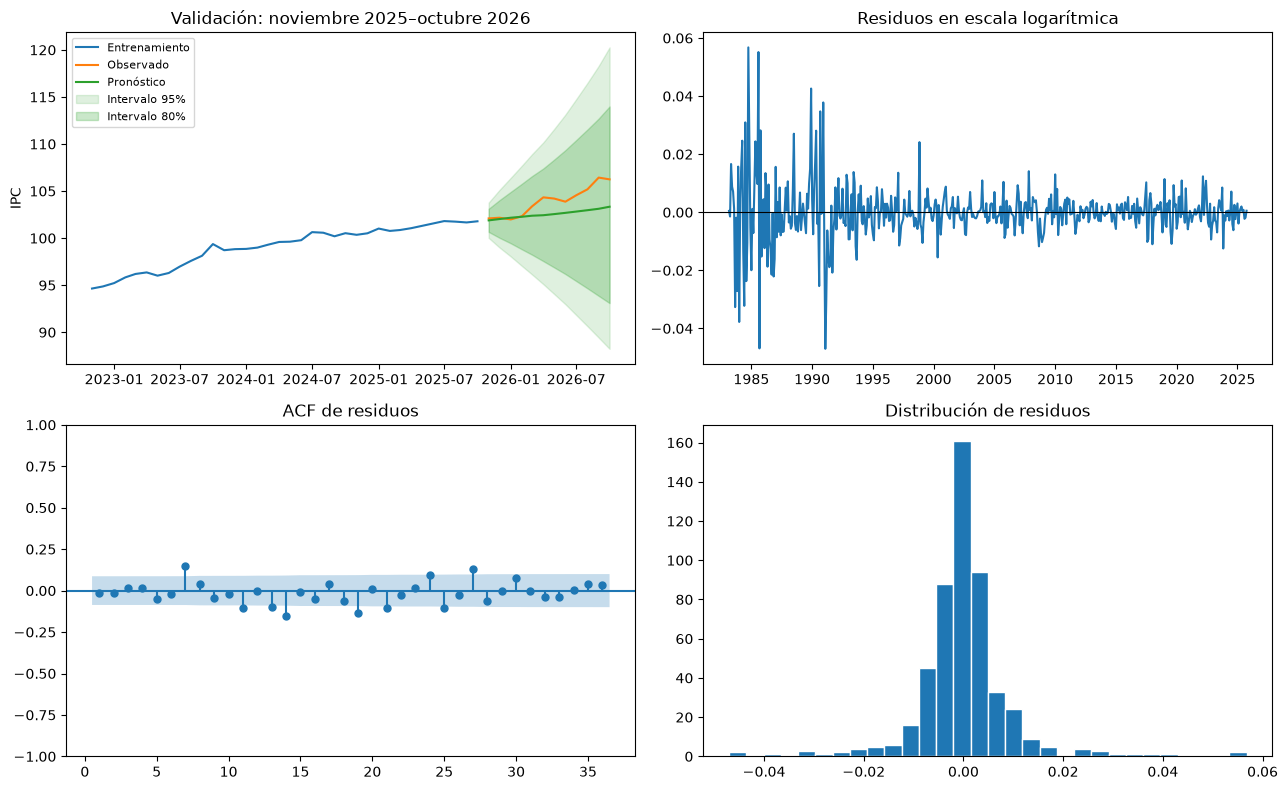

In [7]:
residuos = np.asarray(modelo_seleccionado.model_["residuals"])
residuos = residuos[np.isfinite(residuos)]
grados_modelo = p + q + P + Q
rezago = max(24, grados_modelo + 3)

print("\nLJUNG–BOX")
print(acorr_ljungbox(
    residuos, lags=[rezago], model_df=grados_modelo, return_df=True
).round(4))

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
ax = ejes[0, 0]
ax.plot(datos.index[-h-36:-h], y_train[-36:], label="Entrenamiento")
ax.plot(resultados.index, y_test, label="Observado")
ax.plot(resultados.index, pred["pronostico"], label="Pronóstico")
for nivel, alfa in [(95, 0.15), (80, 0.25)]:
    ax.fill_between(
        resultados.index, pred[f"inferior_{nivel}"], pred[f"superior_{nivel}"],
        color="C2", alpha=alfa, label=f"Intervalo {nivel}%"
    )
ax.set(title="Validación: noviembre 2025–octubre 2026", ylabel="IPC")
ax.legend(fontsize=8)

ejes[0, 1].plot(datos.index[:-h], residuos)
ejes[0, 1].axhline(0, color="black", linewidth=0.8)
ejes[0, 1].set_title("Residuos en escala logarítmica")
plot_acf(residuos, lags=36, ax=ejes[1, 0], zero=False)
ejes[1, 0].set_title("ACF de residuos")
ejes[1, 1].hist(residuos, bins=30, edgecolor="white")
ejes[1, 1].set_title("Distribución de residuos")
fig.tight_layout()
plt.show()

El modelo falló 2 supuestos estadísticos.
- En la tercera figura, ACF de residuos, varios puntos se encuentran fuera de la franja celeste. El modelo falla en capturar información ya que sus residuos están correlacionados. Esta afirmación es apoyada con el valor p de LJUNG BOX (p=0.0). Se probará eliminar una diferencial.
- En la segunda figura, Residuos en escala logarítmica, el ancho de los residuos no es constante. El modelo falla el supuesto de varianza constante, se probará acortar la ventana de observación a únicamente los últimos 15 años.

### 7. MEJORA DEL MODELO


Se implementan los cambios necesarios para eliminar los problemas del modelo anterior.

,MAE,RMSE,MAPE
Original,1.3751,1.7366,1.3092
Mejorado,0.6524,0.8428,0.6220


,lb_stat,lb_pvalue
24,25.116427,0.197013


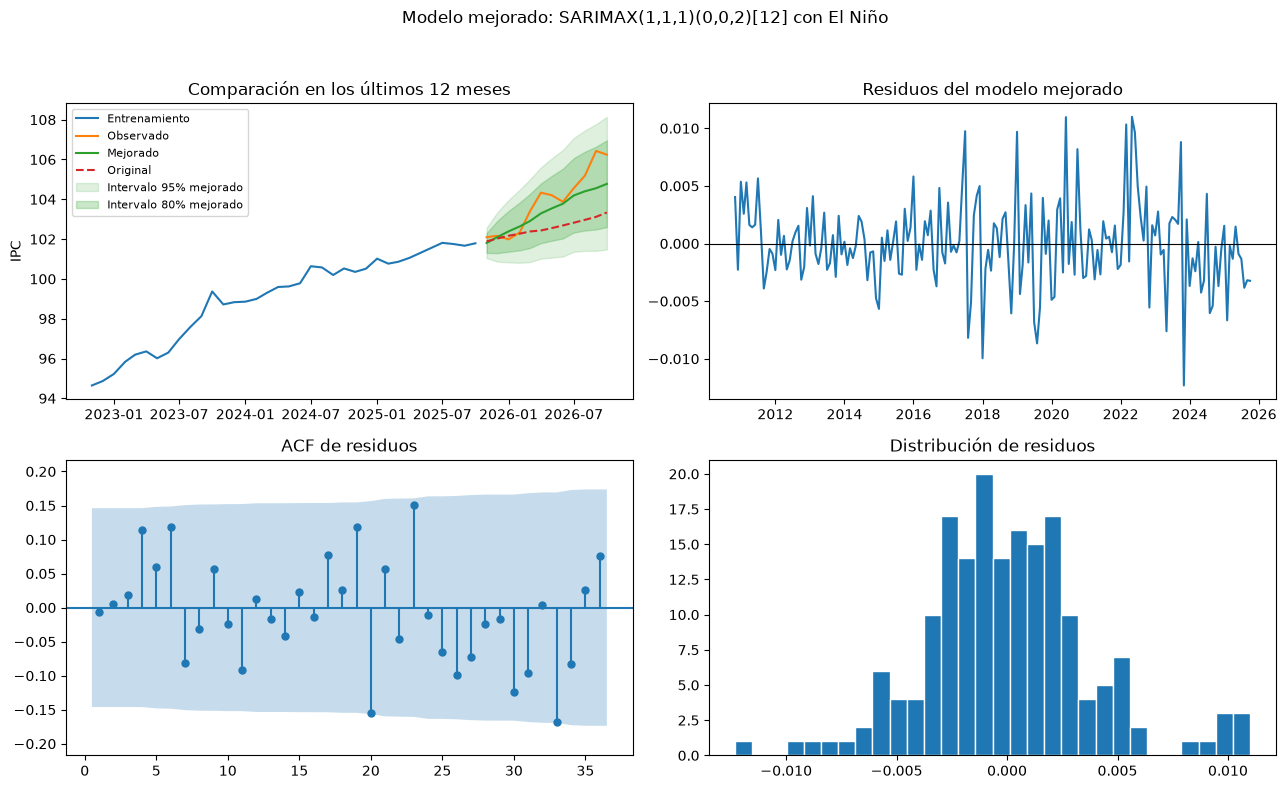

In [8]:

# Mantener el mismo período de prueba del modelo original
train_mejora = datos.iloc[-(180 + h):-h]
test_mejora = datos.iloc[-h:]

y_train_mejora = train_mejora["ipc"].to_numpy(dtype=float)
y_test_mejora = test_mejora["ipc"].to_numpy(dtype=float)
x_train_mejora = train_mejora[["nino"]].to_numpy(dtype=float)
x_test_mejora = test_mejora[["nino"]].to_numpy(dtype=float)

# Ajustar la especificación elegida con una diferencia regular y deriva. (Escogimos D=1 porque mejora disminuye la cantidad de correlación de los residuos.
modelo_mejorado = ARIMA(
    order=(1, 1, 1),
    seasonal_order=(0, 0, 2),
    season_length=12,
    include_mean=False,
    include_drift=True
).fit(np.log(y_train_mejora), X=x_train_mejora)

pred_mejora = predecir(
    modelo_mejorado, x_test_mejora, (0,), h
)

resultados_mejora = pd.DataFrame(
    {"observado": y_test_mejora, **pred_mejora},
    index=test_mejora.index
)

# Comparar ambos modelos sobre los mismos meses
comparacion = pd.DataFrame({
    "Original": metricas(y_test, pred["pronostico"]),
    "Mejorado": metricas(y_test_mejora, pred_mejora["pronostico"])
}).T

display(comparacion.round(4))

# Diagnosticar los residuos del modelo mejorado
residuos_mejora = np.asarray(modelo_mejorado.model_["residuals"])
validos_mejora = np.isfinite(residuos_mejora)
fechas_residuos_mejora = train_mejora.index[validos_mejora]
residuos_mejora = residuos_mejora[validos_mejora]

grados_mejora = sum(modelo_mejorado.model_["arma"][:4])

display(acorr_ljungbox(
    residuos_mejora,
    lags=[24],
    model_df=grados_mejora,
    return_df=True
))

# Gráficos del modelo mejorado
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle(
    "Modelo mejorado: SARIMAX(1,1,1)(0,0,2)[12] con El Niño"
)

ax = ejes[0, 0]
ax.plot(
    train_mejora.index[-36:], y_train_mejora[-36:],
    label="Entrenamiento"
)
ax.plot(
    test_mejora.index, y_test_mejora,
    label="Observado", color="C1"
)
ax.plot(
    test_mejora.index, pred_mejora["pronostico"],
    label="Mejorado", color="C2"
)
ax.plot(
    resultados.index, pred["pronostico"],
    label="Original", color="C3", linestyle="--"
)

for nivel, alfa in [(95, 0.15), (80, 0.25)]:
    ax.fill_between(
        test_mejora.index,
        pred_mejora[f"inferior_{nivel}"],
        pred_mejora[f"superior_{nivel}"],
        color="C2", alpha=alfa, label=f"Intervalo {nivel}% mejorado"
    )

ax.set(title="Comparación en los últimos 12 meses", ylabel="IPC")
ax.legend(fontsize=8)

ejes[0, 1].plot(fechas_residuos_mejora, residuos_mejora)
ejes[0, 1].axhline(0, color="black", linewidth=0.8)
ejes[0, 1].set_title("Residuos del modelo mejorado")

plot_acf(
    residuos_mejora, lags=36, zero=False,
    auto_ylims=True, ax=ejes[1, 0]
)
ejes[1, 0].set_title("ACF de residuos")

ejes[1, 1].hist(residuos_mejora, bins=30, edgecolor="white")
ejes[1, 1].set_title("Distribución de residuos")

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


El segundo modelo es el siguiente: SARIMAX (1,1,1)(0,0,2) [12] con el niño. Su interpretación es la siguiente:

- Cada periodo depende del periodo anterior como punto de partida.
- La tendencia de los datos se puede linealizar diferenciandola una vez. Este cambio se realizó para no sobreajustar el modelo.
- Considera el error del período anterior para ajustar el pronóstico.
- Considera el error de los 2 periodos anuales anteriores para ajustar el pronóstico.

Este modelo mejoró cada una de las métricas x2. Esto es altamente favorable considerando también que eliminó sus problemas residuales. 
Este es el modelo final.

## Coeficientes departamentales

Al poder pronosticar el IPC de los próximos meses, podemos anticipar cómo podrían cambiar los precios en el país conforme pasa el tiempo y según la presencia del fenómeno de El Niño. De por sí, esta información es altamente útil, pero queremos aprovechar al máximo los datos que levanta el INE y llevar nuestro pronóstico a un contexto más específico: cada departamento.

Para hacerlo, utilizaremos los precios recolectados por el INE para calcular el costo de una canasta comparable en cada departamento. Luego aplicaremos la variación del IPC pronosticado a esos costos. Así, podremos estimar cómo evolucionaría el costo de esa canasta en cada departamento, suponiendo que sigue el comportamiento porcentual de los precios nacionales.

In [9]:
df = pd.read_csv(CRUDOS / "precios_recolectados_2023.csv", encoding="utf-8-sig", low_memory=False).rename(columns={
    "Año": "anio", "Mes": "mes", "Cod_Depto.": "depto",
    "Nombre_depto.": "nombre", "Cod_artículo": "articulo",
    "Cantidad": "cantidad", "Precio": "precio"
})

# Excluir faltantes e inválidos, sin imputar.
cols = ["anio", "mes", "depto", "articulo", "cantidad", "precio"]
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=cols)
df = df.loc[(df[cols] > 0).all(axis=1) & df.mes.le(12)].copy()
nombres = df.groupby("depto").nombre.first()

# Promedio de log(precio) por departamento, artículo, cantidad y mes.
claves = ["anio", "mes", "articulo", "cantidad"]
c = df.assign(z=np.log(df.precio)).groupby(
    claves + ["depto"], as_index=False
).agg(z=("z", "mean"), n=("z", "size"))
c = c.loc[c.groupby(claves).depto.transform("nunique").ge(2)].copy()
if c.empty:
    raise ValueError("No hay comparaciones entre departamentos.")

def matriz(c):
    g = c.groupby(claves, sort=False).ngroup().to_numpy()
    d, deptos = pd.factorize(c.depto, sort=True)
    B = csr_matrix((np.ones(len(c)), (g, d)))
    return g, d, np.asarray(deptos), B

# Mantener departamentos conectados por comparaciones comunes.
g, d, deptos, B = matriz(c)
_, componentes = connected_components(B.T @ B, directed=False)
c = c.loc[c.depto.isin(deptos[
    componentes == np.bincount(componentes).argmax()
])].copy()
g, d, deptos, B = matriz(c)

# Regresión con controles de artículo-cantidad-mes.
m = np.asarray(B.sum(axis=1)).ravel()
L = np.diag(np.asarray(B.sum(axis=0)).ravel()) - (B.T @ diags(1/m) @ B).toarray()
r = np.bincount(d, weights=c.z.to_numpy() - (np.bincount(g, weights=c.z)/m)[g])
efectos = np.linalg.solve(L + np.ones_like(L), r)
factores = np.exp(efectos - efectos.max())

coeficientes = pd.DataFrame(index=nombres.index)
coeficientes["departamento"] = nombres
coeficientes["coeficiente"] = pd.Series(factores / factores.mean(), index=deptos)
coeficientes["# Observaciones"] = c.groupby("depto").n.sum().reindex(nombres.index, fill_value=0).astype(int)
coeficientes = coeficientes.reset_index(drop=True)

coeficientes

,departamento,coeficiente,# Observaciones
0,GUATEMALA,1.043917,84481
1,EL PROGRESO,1.015965,9628
2,SACATEPEQUEZ,1.016931,14323
3,CHIMALTENANGO,0.969006,8554
4,ESCUINTLA,0.969105,16118
5,SANTA ROSA,0.965592,7078
6,SOLOLA,0.979291,13618
7,TOTONICAPAN,1.014022,20433
8,QUETZALTENANGO,1.017261,23065
9,SUCHITEPEQUEZ,0.966566,13097


## Pronóstico nacional y departamental

Pronóstico de IPC utilizando el modelo y la estimación departamental. Se debe seleccionar el rango de medición y escribir en el cuadro, separado por comas, los periodos donde se espera el fenómeno del niño.

In [10]:
# Ajustar el modelo final con los últimos 15 años disponibles
historial = datos.tail(180)
modelo_futuro = ARIMA(
    order=(1, 1, 1),
    seasonal_order=(0, 0, 2),
    season_length=12,
    include_mean=False,
    include_drift=True
).fit(
    np.log(historial["ipc"].to_numpy(dtype=float)),
    X=historial[["nino"]].to_numpy(dtype=float)
)
print(f"Efecto de El Niño en el IPC: ({100 * np.expm1(modelo_futuro.model_['coef']['ex_1']):+.4f}%)")

# Crear el panel de pronóstico
@widgets.interact_manual.options(manual_name="Pronosticar")
def pronosticar(
    periodos=widgets.IntSlider(value=12, min=1, max=24, description="Meses:"),
    meses_nino=widgets.Text(
        description="El Niño:", placeholder="Períodos: 1,2,3..."
    )
):
    meses = [int(m.strip()) for m in meses_nino.split(",") if m.strip()]
    if any(m not in range(1, periodos + 1) for m in meses):
        raise ValueError("Los períodos con El Niño deben estar dentro del horizonte.")

    # Fechas y escenario: los períodos no indicados tendrán nino = 0
    fechas = pd.date_range(
        historial.index[-1] + pd.offsets.MonthBegin(1),
        periods=periodos, freq="MS", name="fecha"
    )
    x = np.isin(np.arange(1, periodos + 1), meses).astype(float).reshape(-1, 1)
    prediccion = predecir(modelo_futuro, x, (0,), periodos)

    nacional = pd.DataFrame(
        {"nino": x[:, 0].astype(int), **prediccion}, index=fechas
    )

    # Aplicar los coeficientes departamentales
    departamental = nacional.reset_index().merge(
        coeficientes[["departamento", "coeficiente"]].dropna(),
        how="cross"
    )
    columnas = list(prediccion)
    departamental[columnas] = departamental[columnas].mul(
        departamental["coeficiente"], axis=0
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(historial.index[-36:], historial["ipc"].iloc[-36:], label="Observado")
    ax.plot(fechas, nacional["pronostico"], label="Pronóstico", color="C2")
    ax.fill_between(
        fechas, nacional["inferior_95"], nacional["superior_95"],
        color="C2", alpha=0.2, label="Intervalo 95%"
    )
    ax.set(title="Pronóstico del IPC nacional", xlabel="Fecha", ylabel="IPC")
    ax.legend()
    fig.tight_layout()
    plt.show()

    display(nacional.round(4))
    display(departamental.round(4))

Efecto de El Niño en el IPC: (+0.1537%)


interactive(children=(IntSlider(value=12, description='Meses:', max=24, min=1), Text(value='', continuous_upda…

## Exportación para el sitio web

In [ ]:
# 8. EXPORTAR RESULTADOS PARA EL SITIO WEB --------------------------------
# Escribe en web/public/datos/ipc/ los archivos que lee la sección del IPC.
# No cambia ningún resultado: solo guarda lo que calcularon las celdas anteriores.
import json

SALIDA = RAIZ / "web" / "public" / "datos" / "ipc"
SALIDA.mkdir(parents=True, exist_ok=True)


def escribir(nombre, contenido):
    texto = json.dumps(contenido, ensure_ascii=False, indent=1) + "\n"
    (SALIDA / nombre).write_text(texto, encoding="utf-8")


def mes(fecha):
    return fecha.strftime("%Y-%m-%d")


escribir("serie.json", [
    {"fecha": mes(f), "ipc": round(float(v), 4)} for f, v in datos["ipc"].items()
])

ljung_box = acorr_ljungbox(residuos_mejora, lags=[24], model_df=grados_mejora, return_df=True)
escribir("validacion.json", {
    "modelo": "SARIMAX(1,1,1)(0,0,2)[12] con deriva y El Niño como variable externa",
    "entrenamiento": {"inicio": mes(train_mejora.index[0]), "fin": mes(train_mejora.index[-1])},
    "prueba": {"inicio": mes(test_mejora.index[0]), "fin": mes(test_mejora.index[-1])},
    "metricas": {k: round(float(v), 4) for k, v in metricas(y_test_mejora, pred_mejora["pronostico"]).items()},
    "ljung_box_p": round(float(ljung_box["lb_pvalue"].iloc[0]), 4),
    "meses": [
        {"fecha": mes(f), **{k: round(float(v), 4) for k, v in fila.items()}}
        for f, fila in resultados_mejora.iterrows()
    ],
})

escribir("coeficientes.json", {
    "anio_precios": 2023,
    "departamentos": [
        {
            "codigo": int(codigo),
            "nombre": fila.departamento,
            "coeficiente": round(float(fila.coeficiente), 4),
            "observaciones": int(fila[2]),
        }
        for codigo, fila in zip(nombres.index, coeficientes.itertuples(index=False))
    ],
})

print("Archivos escritos en", SALIDA)